[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gianni04/portfolio-value-at-risk/blob/main/portfolio_var.ipynb)

# Portfolio Value at Risk: models and backtest

One-day 99% VaR and Expected Shortfall of a multi-asset portfolio held by a EUR investor,
with four models, then a rolling out-of-sample backtest (Kupiec and Christoffersen tests).

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import xlogy

WEIGHTS = {
    "MC.PA": 0.10, "SAN.PA": 0.10, "OR.PA": 0.10, "AIR.PA": 0.10,  # Paris, EUR
    "AAPL": 0.10, "MSFT": 0.10, "NVDA": 0.10,                        # US, USD
    "TLT": 0.20,                                                     # US Treasuries ETF, USD
    "ETH-USD": 0.10,                                                 # Ethereum, USD
}
USD_ASSETS = ["AAPL", "MSFT", "NVDA", "TLT", "ETH-USD"]
START, END = "2020-01-01", "2026-01-01"
ALPHA = 0.99      # confidence level
WINDOW = 250      # rolling window for the backtest (1 year)
SEED = 42

tickers = list(WEIGHTS)
w = np.array(list(WEIGHTS.values()))

## Data

Prices from Yahoo Finance (adjusted closes). USD assets are converted to EUR with EURUSD, so the
FX risk is part of the portfolio risk. Only days where every asset has a close are kept: Ethereum
trades every day, so its weekend moves are included in the Monday return. Returns are simple
returns (they add up across assets with the weights; log returns do not), and the portfolio is
rebalanced daily to the fixed weights.

In [2]:
raw = yf.download(tickers + ["EURUSD=X"], start=START, end=END, auto_adjust=True, progress=False)["Close"]
eurusd = raw["EURUSD=X"].ffill()                    # USD per 1 EUR

prices = raw[tickers].copy()
prices[USD_ASSETS] = prices[USD_ASSETS].div(eurusd, axis=0)
prices = prices.dropna()

returns = prices.pct_change().dropna()
port = returns @ w

print(f"{len(port)} daily returns, {port.index[0].date()} to {port.index[-1].date()}")
print(f"annualised vol {port.std() * np.sqrt(252):.1%}, skew {stats.skew(port):.2f}, excess kurtosis {stats.kurtosis(port):.1f}")

1494 daily returns, 2020-01-03 to 2025-12-31
annualised vol 20.2%, skew -0.42, excess kurtosis 6.8


## VaR and ES on the full sample

VaR and ES are reported as positive losses in % of the portfolio, with a zero mean (standard for a
one-day horizon).

- **Historical**: empirical 1% quantile, ES = average of the returns beyond it
- **Normal**: volatility times the normal quantile
- **Student-t**: t distribution fitted by maximum likelihood (fat tails)
- **Monte Carlo**: 100,000 joint scenarios for the 9 assets from a multivariate Student-t with the
  sample covariance, then revalued with the weights

In [3]:
def historical(r, a=ALPHA):
    q = np.quantile(r, 1 - a)
    return -q, -r[r <= q].mean()

def normal(r, a=ALPHA):
    s, z = r.std(), stats.norm.ppf(a)
    return z * s, s * stats.norm.pdf(z) / (1 - a)

def student_t(r, a=ALPHA):
    nu, _, scale = stats.t.fit(r, floc=0)
    q = stats.t.ppf(a, nu)
    es = scale * stats.t.pdf(q, nu) / (1 - a) * (nu + q**2) / (nu - 1)
    return scale * q, es

def monte_carlo_t(rets, weights, a=ALPHA, n=100_000, seed=SEED):
    rng = np.random.default_rng(seed)
    nu, _, _ = stats.t.fit(rets @ weights, floc=0)
    L = np.linalg.cholesky(rets.cov().values)
    z = rng.standard_normal((n, len(weights))) @ L.T
    chi = rng.chisquare(nu, size=(n, 1))
    sims = z / np.sqrt(chi / nu) * np.sqrt((nu - 2) / nu)   # same covariance, fat tails
    return historical(pd.Series(sims @ weights), a)

results = pd.DataFrame({
    "Historical": historical(port),
    "Normal": normal(port),
    "Student-t": student_t(port),
    "Monte Carlo (t)": monte_carlo_t(returns, w),
}, index=["VaR 99%", "ES 99%"]).T
print((results * 100).round(2).to_string())

                 VaR 99%  ES 99%
Historical          3.37    4.77
Normal              2.97    3.40
Student-t           3.37    4.63
Monte Carlo (t)     3.40    4.65


In [4]:
print("5 worst days:")
print((port.nsmallest(5) * 100).round(2).to_string())
var_ex, es_ex = historical(port[port.index >= "2021-01-01"])
print(f"\nHistorical ES without 2020: {es_ex:.2%} (with 2020: {results.loc['Historical', 'ES 99%']:.2%})")

5 worst days:
Date
2020-03-12   -11.06
2020-03-09    -7.06
2020-03-16    -6.08
2022-06-13    -5.45
2020-03-18    -4.79

Historical ES without 2020: 3.70% (with 2020: 4.77%)


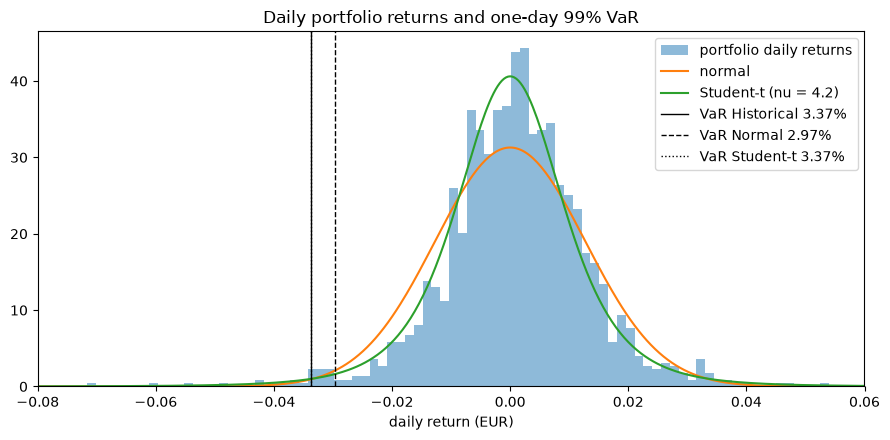

In [5]:
x = np.linspace(-0.08, 0.06, 400)
nu, _, scale = stats.t.fit(port, floc=0)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(port, bins=120, density=True, alpha=0.5, label="portfolio daily returns")
ax.plot(x, stats.norm.pdf(x, 0, port.std()), label="normal")
ax.plot(x, stats.t.pdf(x, nu, 0, scale), label=f"Student-t (nu = {nu:.1f})")
for name, ls in [("Historical", "-"), ("Normal", "--"), ("Student-t", ":")]:
    ax.axvline(-results.loc[name, "VaR 99%"], ls=ls, color="k", lw=1,
               label=f"VaR {name} {results.loc[name, 'VaR 99%']:.2%}")
ax.set_xlim(-0.08, 0.06)
ax.set_title("Daily portfolio returns and one-day 99% VaR")
ax.set_xlabel("daily return (EUR)")
ax.legend()
plt.tight_layout()
plt.show()

## Backtest

Each day, the VaR is estimated on the previous 250 days only, then compared with the next day's
return. A breach is a loss larger than the VaR. At 99%, about 1% of days should be breaches.

- **Kupiec**: is the number of breaches consistent with 1%?
- **Christoffersen**: are breaches independent, or do they come in clusters?
- **EWMA**: normal VaR with a RiskMetrics volatility (lambda = 0.94), which reacts faster to new volatility.

In [6]:
def ewma(r, a=ALPHA, lam=0.94):
    wts = lam ** np.arange(len(r))[::-1]
    s = np.sqrt((wts * r.values**2).sum() / wts.sum())
    return stats.norm.ppf(a) * s, np.nan

models = {"Historical": historical, "Normal": normal, "EWMA": ewma, "Student-t": student_t}
var = pd.DataFrame(
    {name: [f(port.iloc[i - WINDOW:i])[0] for i in range(WINDOW, len(port))] for name, f in models.items()},
    index=port.index[WINDOW:],
)
realised = port.iloc[WINDOW:]
breaches = var.apply(lambda v: realised < -v)

In [7]:
def kupiec(hits, p=1 - ALPHA):
    n, x = len(hits), hits.sum()
    lr = -2 * (xlogy(n - x, 1 - p) + xlogy(x, p) - xlogy(n - x, 1 - x / n) - xlogy(x, x / n))
    return 1 - stats.chi2.cdf(lr, 1)

def christoffersen(hits):
    h = hits.astype(int).values
    n00 = ((h[:-1] == 0) & (h[1:] == 0)).sum(); n01 = ((h[:-1] == 0) & (h[1:] == 1)).sum()
    n10 = ((h[:-1] == 1) & (h[1:] == 0)).sum(); n11 = ((h[:-1] == 1) & (h[1:] == 1)).sum()
    p01, p11 = n01 / (n00 + n01), n11 / max(n10 + n11, 1)
    p = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll_indep = xlogy(n00 + n10, 1 - p) + xlogy(n01 + n11, p)
    ll_markov = xlogy(n00, 1 - p01) + xlogy(n01, p01) + xlogy(n10, 1 - p11) + xlogy(n11, p11)
    return 1 - stats.chi2.cdf(-2 * (ll_indep - ll_markov), 1)

backtest = pd.DataFrame({
    "breaches": breaches.sum(),
    "expected": round(len(realised) * (1 - ALPHA), 1),
    "rate %": (breaches.mean() * 100).round(2),
    "Kupiec p": breaches.apply(kupiec).round(3),
    "Christoffersen p": breaches.apply(christoffersen).round(3),
})
print(f"{len(realised)} out-of-sample days, {realised.index[0].date()} to {realised.index[-1].date()}")
print(backtest.to_string())

1244 out-of-sample days, 2021-01-04 to 2025-12-31
            breaches  expected  rate %  Kupiec p  Christoffersen p
Historical        19      12.4    1.53     0.083             0.032
Normal            20      12.4    1.61     0.048             0.039
EWMA              21      12.4    1.69     0.026             0.048
Student-t         12      12.4    0.96     0.900             0.004


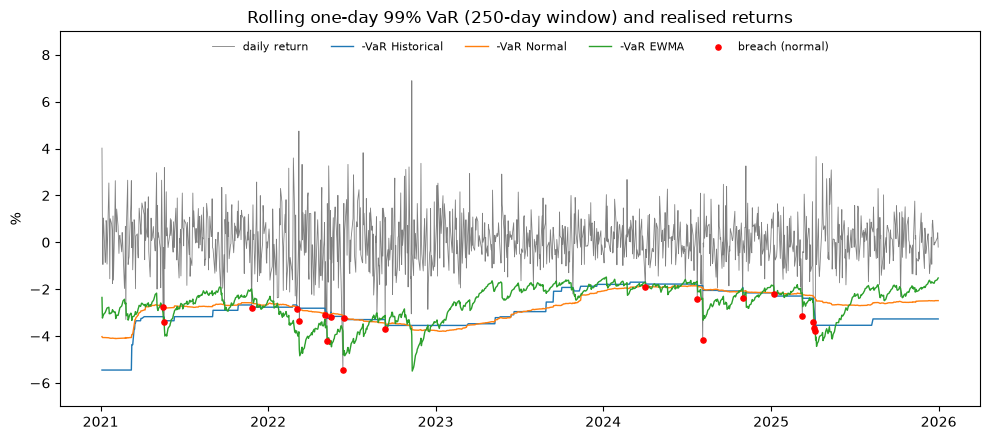

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(realised.index, realised * 100, lw=0.6, color="grey", label="daily return")
for name in ["Historical", "Normal", "EWMA"]:
    ax.plot(var.index, -var[name] * 100, lw=1, label=f"-VaR {name}")
hits = breaches["Normal"]
ax.scatter(realised.index[hits], realised[hits] * 100, color="red", s=14, zorder=3, label="breach (normal)")
ax.set_ylabel("%")
ax.set_title("Rolling one-day 99% VaR (250-day window) and realised returns")
ax.set_ylim(-7, 9)
ax.legend(loc="upper center", ncol=5, fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

## Where the risk comes from

Contribution of each asset to the portfolio volatility (weight x marginal contribution, they add
up to 100%).

In [9]:
cov = returns.cov()
contrib = w * (cov.values @ w) / (w @ cov.values @ w)
risk = pd.DataFrame({"weight %": w * 100, "risk contribution %": contrib * 100}, index=tickers).round(1)
print(risk.sort_values("risk contribution %", ascending=False).to_string())

         weight %  risk contribution %
ETH-USD      10.0                 28.3
NVDA         10.0                 18.5
AAPL         10.0                 11.1
MSFT         10.0                 10.8
AIR.PA       10.0                  9.9
MC.PA        10.0                  8.8
OR.PA        10.0                  6.2
SAN.PA       10.0                  3.2
TLT          20.0                  3.2
